# 第2章 数据的读取与处理课堂练习参考代码
对应课件第 70 页的 5 道题（2 基础 + 2 进阶 + 1 挑战）

基础题1：
读取 data/sales_2026.csv，打印 shape、info() 和前 5 行，
并统计每列缺失值个数与占比

In [2]:
import pandas as pd
df = pd.read_csv('data/sales_2026.csv', encoding='utf-8-sig')

print('shape =', df.shape)
df.info()
print('\nhead()：')
print(df.head())

miss = df.isnull().sum()
ratio = (miss / len(df) * 100).round(2)
report = pd.DataFrame({'缺失个数': miss, '缺失占比%': ratio})
print('\n每列缺失情况：')
print(report)

shape = (1200, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   order_id    1200 non-null   object 
 1   order_time  1200 non-null   object 
 2   store       1194 non-null   object 
 3   category    1200 non-null   object 
 4   amount      1158 non-null   float64
 5   quantity    1200 non-null   int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 56.4+ KB

head()：
     order_id           order_time store category  amount  quantity
0  D260301001  2026-03-01 09:12:00    A店       家电  1280.0         2
1  D260301002  2026-03-01 09:35:00    B店       图书   158.0         1
2  D260301003  2026-03-01 10:02:00    A店       服饰   399.0         3
3  D260301004  2026-03-01 10:41:00    C店       家电   899.0         1
4  D260301005  2026-03-01 11:08:00    B店       食品    76.0         4

每列缺失情况：
            缺失个数  缺失占比%
order_id       0    0.0
order_time 

基础题 2：把 order_time 列转为 datetime64，再分别按年、月、星期统计订单量

In [3]:
df = df.copy()
df['order_time'] = pd.to_datetime(df['order_time'])
df['year'] = df['order_time'].dt.year
df['month'] = df['order_time'].dt.month
df['weekday'] = df['order_time'].dt.dayofweek      # 周一=0，周日=6
print('按年：')
print(df.groupby('year').size())
print('\n按月：')
print(df.groupby('month').size())
print('\n按星期（0=周一 … 6=周日）：')
print(df.groupby('weekday').size())
    
# 进阶写法：一次求出多个时间维度
print('\n交叉查看 月 × 星期：')
print(pd.crosstab(df['month'], df['weekday']))

按年：
year
2026    1200
dtype: int64

按月：
month
3    424
4    413
5    363
dtype: int64

按星期（0=周一 … 6=周日）：
weekday
0    179
1    174
2    168
3    172
4    165
5    167
6    175
dtype: int64

交叉查看 月 × 星期：
weekday   0   1   2   3   4   5   6
month                              
3        72  64  53  50  59  56  70
4        59  58  64  68  54  56  54
5        48  52  51  54  52  55  51


进阶题 3：用箱线图找出 amount 列的异常值，分别用「删除」和「截断」两种方式处理，对比 describe() 的差异

IQR 准则：Q1=168.75  Q3=762.50  IQR=593.75
判定区间：[-721.88, 1653.12]
异常值 29 条
（绘图环境不可用，跳过绘图：NameError）


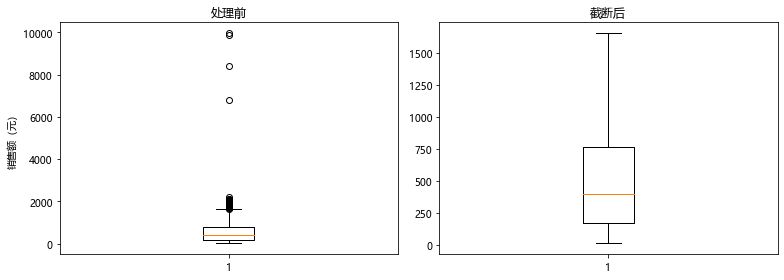

In [4]:
s = df['amount'].dropna()
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f'IQR 准则：Q1={q1:.2f}  Q3={q3:.2f}  IQR={iqr:.2f}')
print(f'判定区间：[{lo:.2f}, {hi:.2f}]')
print(f'异常值 {((s > hi) | (s < lo)).sum()} 条')

# 画箱线图（需要 matplotlib）
try:
    import matplotlib.pyplot as plt
    plt.rcParams['font.family'] = 'Microsoft YaHei'
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].boxplot(s, vert=True)
    axes[0].set_title('处理前')
    axes[0].set_ylabel('销售额（元）')
    axes[1].boxplot(s.clip(lo, hi), vert=True)
    axes[1].set_title('截断后')
    plt.tight_layout()
    plt.savefig(os.path.join(BASE, 'output', 'ex3_boxplot.png'), dpi=150)
    print('箱线图已保存到 output/ex3_boxplot.png')
except Exception as e:
    print(f'（绘图环境不可用，跳过绘图：{type(e).__name__}）')
    

In [5]:
# 方式一：删除
deleted = df[~((df['amount'] > hi) | (df['amount'] < lo))]
    
# 方式二：截断（盖帽法，保留记录但压缩极值）
clipped = df.copy()
clipped['amount'] = clipped['amount'].clip(lo, hi)
cmp = pd.DataFrame({
    '原始': s.describe(),
    '删除后': deleted['amount'].describe(),
    '截断后': clipped['amount'].describe(),
}).round(2)
print('\n三种处理方式的 describe() 对比：')
print(cmp)
print(f"\n样本量：原始 {len(s)} → 删除后 {deleted['amount'].count()} "
         f"→ 截断后 {clipped['amount'].count()}")
print('\n差异解读：')
print('  · 删除法：样本量下降，均值与标准差显著变小，可能丢失真实的大额订单')
print('  · 截断法：样本量不变，极值被压到边界，均值变化小但分布被人为截平')


三种处理方式的 describe() 对比：
            原始      删除后      截断后
count  1158.00  1129.00  1158.00
mean    567.37   508.73   537.39
std     667.01   410.63   443.17
min      12.00    12.00    12.00
25%     168.75   164.82   168.75
50%     398.00   386.51   398.00
75%     762.50   735.09   762.50
max    9980.00  1636.74  1653.12

样本量：原始 1158 → 删除后 1129 → 截断后 1158

差异解读：
  · 删除法：样本量下降，均值与标准差显著变小，可能丢失真实的大额订单
  · 截断法：样本量不变，极值被压到边界，均值变化小但分布被人为截平


进阶题 4：用 pivot_table 生成「门店 × 商品类别」的销售额透视表，并显示合计行列

In [6]:
pv = df.pivot_table(index='store', columns='category', values='amount',
                    aggfunc='sum', fill_value=0, margins=True,
                    margins_name='合计')
print('单位：元')
print(pv.round(2))
print('\n单位：万元，并追加占比')
pv_wan = (pv / 10000).round(2)
print(pv_wan)

单位：元
category         图书         家电         服饰         食品         合计
store                                                          
A店         35934.97  116748.89   41377.14   37900.12  231961.12
B店         67685.44   40268.70   42817.14   50253.34  201024.62
C店         41452.16   67499.14   56540.49   58531.72  224023.51
合计        145072.57  224516.73  140734.77  146685.18  657009.25

单位：万元，并追加占比
category     图书     家电     服饰     食品    合计
store                                     
A店         3.59  11.67   4.14   3.79  23.2
B店         6.77   4.03   4.28   5.03  20.1
C店         4.15   6.75   5.65   5.85  22.4
合计        14.51  22.45  14.07  14.67  65.7


挑战题 5：把销售表与商品信息表按 product_id 合并，统计每个类别的客单价并按降序排列

In [9]:
# 说明：sales_2026.csv 是订单级流水，不直接含 product_id；
#  商品与订单的对应关系保存在「订单商品明细.csv」中。
#  因此需要先按 order_id 桥接，再按 product_id 关联商品信息。
detail = pd.read_csv('data/订单商品明细.csv', encoding='utf-8-sig')
product = pd.read_csv('data/商品信息表.csv', encoding='utf-8-sig')

In [10]:
# 第一步：订单 ↔ 商品明细（按 order_id）
step1 = df.merge(detail, on='order_id', how='inner',
                    suffixes=('', '_d'))

In [11]:
# 第二步：再与商品信息表按 product_id 合并
step2 = step1.merge(product, on='product_id', how='left',
                    suffixes=('', '_p'))
print(f'合并后：{step2.shape[0]} 行（原销售表 {df.shape[0]} 行）')
print('\n合并结果预览：')
print(step2[['order_id', 'store', 'category', 'amount','product_id', 'product_name']].head())

合并后：1791 行（原销售表 1200 行）

合并结果预览：
     order_id store category  amount product_id product_name
0  D260301001    A店       家电  1280.0        P03         双门冰箱
1  D260301001    A店       家电  1280.0        P04          电磁炉
2  D260301002    B店       图书   158.0        P08        统计学原理
3  D260301002    B店       图书   158.0        P10      SQL必知必会
4  D260301003    A店       服饰   399.0        P13          牛仔裤


In [12]:
# 客单价 = 销售额 / 订单数（按商品类别）
# 注意：需先对 order_id 去重，避免同一订单被多个商品重复计数
order_level = (step2[['order_id', 'category_p', 'amount']].drop_duplicates(subset=['order_id']))
result = (order_level.groupby('category_p')
            .agg(订单数=('order_id', 'count'),销售额=('amount', 'sum'),客单价=('amount', 'mean'))
            .round(2)
            .sort_values('客单价', ascending=False))
result.columns = ['订单数', '销售额', '客单价']
print('\n各商品类别客单价（降序）：')
print(result)


各商品类别客单价（降序）：
            订单数        销售额     客单价
category_p                        
食品          244  146685.18  611.19
家电          382  224516.73  608.45
图书          289  145072.57  523.73
服饰          285  140734.77  517.41


In [13]:
# 对照：直接按销售表自带的 category 计算
print('\n对照：按销售表 category 字段直接计算')
print(df.groupby('category')
        .agg(订单数=('order_id', 'count'), 客单价=('amount', 'mean'))
        .round(2).sort_values('客单价', ascending=False))


对照：按销售表 category 字段直接计算
          订单数     客单价
category             
食品        244  611.19
家电        382  608.45
图书        289  523.73
服饰        285  517.41
